Total training compute(in GFLOPs) for models found on the pareto frontier(Scaling laws for robust comparison).

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

C = np.array([7.05e+6, 1.69e+7, 3.5e+7, 7.05e+7, 1.24e+8, 1.69e+8])  # considering first 7 models
Cmin, Cmax = C.min(), C.max()

target_logs = np.linspace(np.log10(Cmin), np.log10(Cmax), 5)

plt.figure()
plt.xscale("log")
plt.scatter(np.log10(C), np.zeros_like(C), label="Actual models")
plt.scatter(target_logs, np.zeros_like(target_logs), marker="x", label="Target log points")

plt.yticks([])
plt.xlabel("log10(GFLOPs)")
plt.legend()
plt.title("Actual compute vs. 5 target log-spaced baseline points")

plt.show()

C = np.array([7.05e+6, 1.5e+7, 1.69e+7, 3.5e+7, 7.05e+7, 1.24e+8, 1.69e+8, 3.52e+8,
              6.23e+8])  # considering first 9 models, assuming we have 64m samples
Cmin, Cmax = C.min(), C.max()

target_logs = np.linspace(np.log10(Cmin), np.log10(Cmax), 5)
plt.figure()
plt.xscale("log")
plt.scatter(np.log10(C), np.zeros_like(C), label="Actual models")
plt.scatter(target_logs, np.zeros_like(target_logs), marker="x", label="Target log points")

plt.yticks([])
plt.xlabel("log10(GFLOPs)")
plt.legend()
plt.title("Actual compute vs. 5 target log-spaced baseline points")

plt.show()

Baseline results plotting

In [ ]:
from train.utils import plot_compute_vs_metric, Plotting

plot_compute_vs_metric("runs_config.csv", Plotting.VALIDATION_ERROR)
plot_compute_vs_metric("runs_config.csv", Plotting.TEST_ERROR)
plot_compute_vs_metric("runs_config.csv", Plotting.IMAGENET)
plot_compute_vs_metric("runs_config.csv", Plotting.MSCOCO_IMG)


Load CLIP model with custom vision and text tower

In [ ]:
from train.utils import precision_to_dtype
from train.clip_train.profiler import get_model_flops
from open_clip import create_model

model = create_model("local-dir:model_configs/ViT-B-32", precision="bf16")

get_model_flops(model, 100, dtype=precision_to_dtype("bf16"))


Batch size heuristic based on pareto frontier

In [ ]:

from train.utils import monotonic_bs, query_bs
import numpy as np

samples_seen = np.array([
    1.28e+06, 1.28e+06, 1.28e+06, 3.07e+06, 6.4e+06, 1.28e+07,
    1.28e+07, 3.07e+07, 6.4e+07, 6.4e+07, 1.28e+08, 1.28e+08,
    3.07e+08, 6.4e+08, 3.07e+08, 6.4e+08, 1.28e+09, 6.4e+08,
    6.4e+08, 1.28e+09, 6.4e+08, 3.07e+09, 1.28e+09, 3.07e+09,
    3.07e+09
], dtype=float)

gflops_per_sample = np.array([
    5.51, 11.75, 11.75, 5.51, 5.51, 5.51, 9.74, 5.51, 5.51, 9.74,
    5.51, 11.75, 5.51, 5.51, 14.3, 9.74, 14.54, 43.59, 46.78, 43.59,
    132.37, 43.59, 168.61, 132.37, 168.61
], dtype=float)

batch_size = np.array([
    512, 512, 512, 1024, 1024, 2048, 2048, 4096, 4096, 4096,
    8192, 8192, 16384, 16384, 16384, 32800, 16384, 45056, 32768, 90624,
    45056, 91136, 90624, 91136, 91136
], dtype=int)

total_compute = samples_seen * gflops_per_sample
total_compute = np.round(total_compute, 3)

ranges = monotonic_bs(total_compute, batch_size)
print(query_bs(705280005))


Infer hardware requirements

In [ ]:
import math

global_batch_size = 90624
local_bs = 128
max_gpus_per_node = 4

gpus_needed = global_batch_size // local_bs
gpus_per_node = min(gpus_needed, max_gpus_per_node)
nodes_nr = math.ceil(gpus_needed / max_gpus_per_node)

print(f"GPUs needed:{gpus_needed}")
print(f"GPUs per node:{gpus_per_node}")
print(f"Nodes number:{nodes_nr}")

In [ ]:
import neps

root_dir = "results/model=ViT-S-32/seed=0"
full_df, result = neps.status(root_dir)
print(full_df)


Max. amount of GFLOPs for our case

In [ ]:
from train.utils import precision_to_dtype
from train.clip_train.profiler import get_model_flops
from open_clip import create_model

nr_defined_samples = 50000000
model = create_model("local-dir:model_configs/ViT-B-32", precision="bf16")

flops_amount = get_model_flops(model, nr_defined_samples, dtype=precision_to_dtype("bf16"))
print(flops_amount)

nr_defined_samples = 66926609
flops_amount = get_model_flops(model, nr_defined_samples, dtype=precision_to_dtype("bf16"))
print(flops_amount)


In [ ]:
from train.utils import build_model_cfg

build_model_cfg(text_width=256, vision_width=413,
                out_path="results/model=ViT-S-32/optimizer=experimental/seed=1/model_cfg/config_1")

GFLOPs to GPU hours mapping

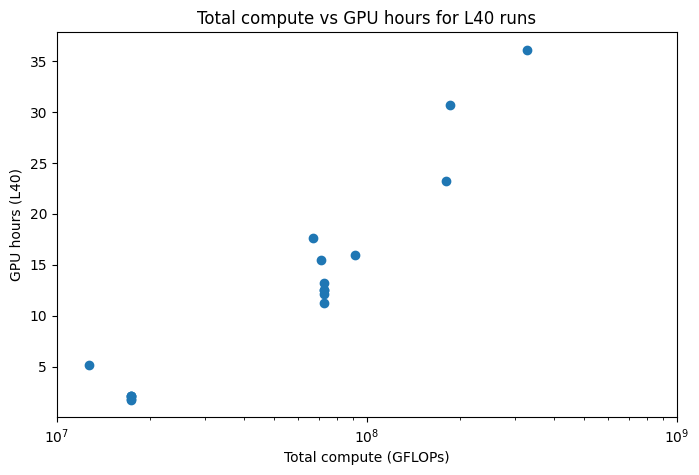

0.00985131025694993


np.float64(19.467715288264298)

In [6]:
from matplotlib.ticker import LogLocator, LogFormatterSciNotation
import pandas as pd
import matplotlib.pyplot as plt

df1 = pd.DataFrame([
    {"gpu_type": "L40", "gpus_used": 4, "total_compute_gflops": 185670231, "train_time_seconds": 27620},
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 66988523, "train_time_seconds": 63392},
    {"gpu_type": "L40", "gpus_used": 4, "total_compute_gflops": 327350517, "train_time_seconds": 32500},
    {"gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 91605729.28, "train_time_seconds": 28736},
    {"gpu_type": "L40", "gpus_used": 4, "total_compute_gflops": 180591657, "train_time_seconds": 20876},
    {"gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 12728729.6, "train_time_seconds": 9289},
    {"gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 71044300.8, "train_time_seconds": 27757},
])

df2 = pd.DataFrame([
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 17376200, "train_time_seconds": 7615.54},
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 17376200, "train_time_seconds": 6688.07},
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 17376200, "train_time_seconds": 7561.76},
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 17376200, "train_time_seconds": 7565.71},
    {"gpu_type": "L40", "gpus_used": 1, "total_compute_gflops": 17376200, "train_time_seconds": 6323.74},
])

df3 = pd.DataFrame([
    {"trial_id": 1, "gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 72448000,
     "train_time_seconds": 23724.24},

    {"trial_id": 2, "gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 72448000,
     "train_time_seconds": 22557.86},

    {"trial_id": 3, "gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 72448000,
     "train_time_seconds": 22557.91},

    {"trial_id": 4, "gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 72448000,
     "train_time_seconds": 20217.83},

    {"trial_id": 5, "gpu_type": "L40", "gpus_used": 2, "total_compute_gflops": 72448000,
     "train_time_seconds": 21887.09},
])

df = pd.concat([df1, df2, df3], ignore_index=True)
df["gpu_hours"] = df["gpus_used"] * (df["train_time_seconds"] / 3600)

plt.figure(figsize=(8, 5))
plt.scatter(df["total_compute_gflops"], df["gpu_hours"])

plt.xscale("log")

plt.xlim(1e7, 1e9)
ax = plt.gca()
ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,)))
ax.xaxis.set_major_formatter(LogFormatterSciNotation())

plt.xlabel("Total compute (GFLOPs)")
plt.ylabel("GPU hours (L40)")
plt.title("Total compute vs GPU hours for L40 runs")
plt.show()

PEAK_GFLOPS_L40 = 181_050  # this is in GFLOPs per second, assuming fp16(we have amp precision, which is dominated by fp16)

weighted_mfu = (
        df["total_compute_gflops"].sum()
        / (
                PEAK_GFLOPS_L40
                * (df["train_time_seconds"] * df["gpus_used"]).sum()
        )
)

print(weighted_mfu)


def estimate_gpu_hours(total_gflops, gpus, mfu, peak_gflops_per_gpu):
    seconds = total_gflops / (gpus * peak_gflops_per_gpu * mfu)
    return seconds / 3600


estimate_gpu_hours(1e9, 8, weighted_mfu, PEAK_GFLOPS_L40) # this assumes max local batch size


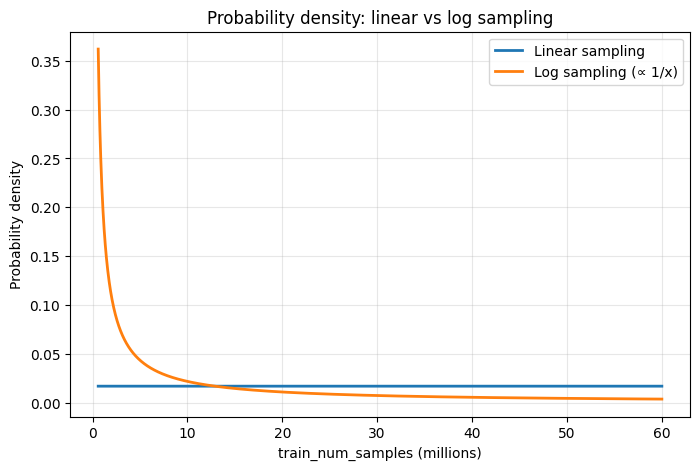

In [1]:
import numpy as np
import matplotlib.pyplot as plt

lower = 0.6
upper = 60.0

x = np.linspace(lower, upper, 2000)

pdf_linear = np.ones_like(x) / (upper - lower)
pdf_log = 1.0 / (x * np.log(upper / lower))

plt.figure(figsize=(8, 5))
plt.plot(x, pdf_linear, label="Linear sampling", linewidth=2)
plt.plot(x, pdf_log, label="Log sampling (∝ 1/x)", linewidth=2)

plt.xlabel("train_num_samples (millions)")
plt.ylabel("Probability density")
plt.title("Probability density: linear vs log sampling")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


Warped log-uniform distribution

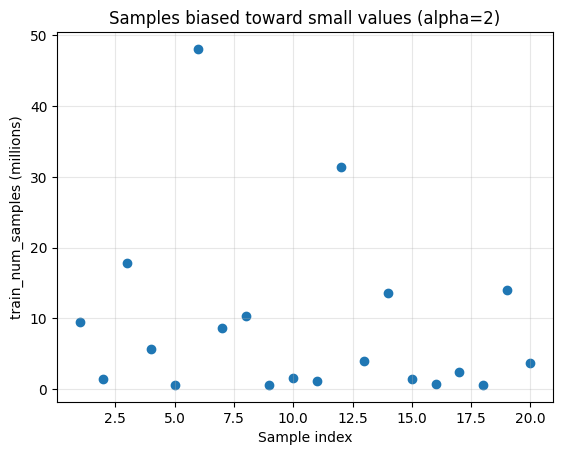

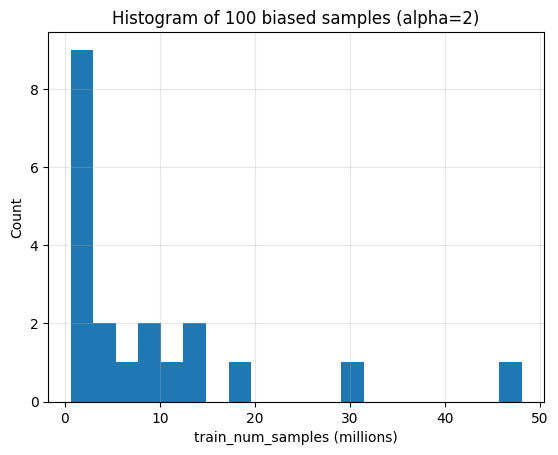

In [37]:
import numpy as np
import matplotlib.pyplot as plt

lower = 0.6
upper = 60.0
n = 20

# alpha = 1.0 pure log-uniform
# alpha > 1.0 increasingly biased toward the lower bound
alpha = 2

rng = np.random.default_rng(42)
u = rng.uniform(0.0, 1.0, size=n)

samples = lower * (upper / lower) ** (u ** alpha)

plt.figure()
plt.scatter(np.arange(1, n + 1), samples)
plt.xlabel("Sample index")
plt.ylabel("train_num_samples (millions)")
plt.title(f"Samples biased toward small values (alpha={alpha})")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.hist(samples, bins=20)
plt.xlabel("train_num_samples (millions)")
plt.ylabel("Count")
plt.title(f"Histogram of 100 biased samples (alpha={alpha})")
plt.grid(True, alpha=0.3)
plt.show()


Polynomial log sampling

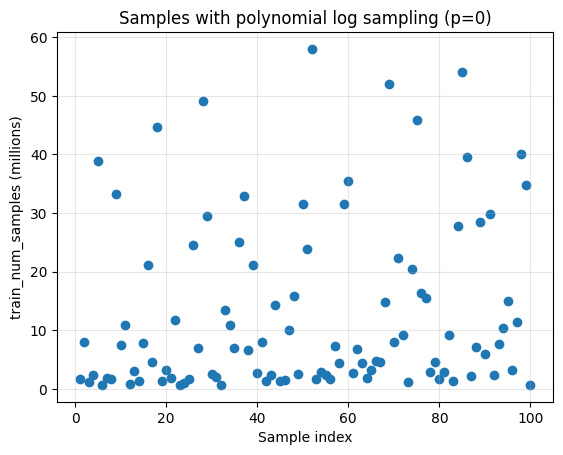

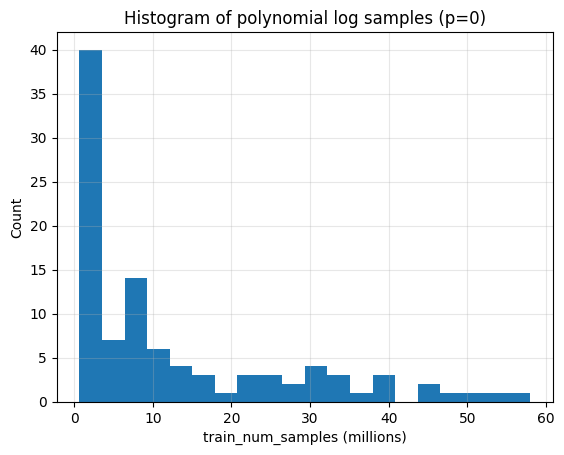

In [31]:
import numpy as np
import matplotlib.pyplot as plt

lower = 0.6
upper = 60.0
n = 100
p = 0

rng = np.random.default_rng(42)
u = rng.uniform(0.0, 1.0, size=n)

z = 1.0 - u ** (1.0 / (p + 1))
samples = lower * (upper / lower) ** z

plt.figure()
plt.scatter(range(1, n + 1), samples)
plt.xlabel("Sample index")
plt.ylabel("train_num_samples (millions)")
plt.title(f"Samples with polynomial log sampling (p={p})")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.hist(samples, bins=20)
plt.xlabel("train_num_samples (millions)")
plt.ylabel("Count")
plt.title(f"Histogram of polynomial log samples (p={p})")
plt.grid(True, alpha=0.3)
plt.show()
